In [75]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from utils.spatial_RF import compute_kernel
from utils.plotting import vector_to_kernel, plot_spatial_kernel_hex

In [76]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [77]:
### GLOBAL VARIABLES
PRE_TYPE_1  = 'Mi1'
PRE_TYPE_2  = 'Mi9'
POST_TYPE = 'T4b'
RADIUS    = 2
SEED      = 1

mean_kernel, kernels_1 = compute_kernel(
    edges,
    pre_type    = PRE_TYPE_1,
    post_type   = POST_TYPE,
    radius      = RADIUS)

M1 = (
        kernels_1
        .assign(                    ##Creates new col called offset: converts the (dp,dq) pair into a col name
            offset=lambda d: (
                d["dp"].astype(int).astype(str)
                + "_"
                + d["dq"].astype(int).astype(str)
            )
        )
        .pivot_table( #reshapes the long table into a wide matrix.
            index="post", #row per post
            columns="offset", #one col per offset
            values="count", #fills each col with summed counts
            aggfunc="sum", #If there are multiple rows with the same (post, offset), add their counts together. I think there should be few
            fill_value=0,
        ).rename_axis(columns=None)   # removes the "offset" label above columns
    # .reset_index()               # turns post from index into first column
    )

mean_kernel, kernels_2 = compute_kernel(
    edges,
    pre_type    = PRE_TYPE_2,
    post_type   = POST_TYPE,
    radius      = RADIUS)

M2 = (
        kernels_2
        .assign(                    ##Creates new col called offset: converts the (dp,dq) pair into a col name
            offset=lambda d: (
                d["dp"].astype(int).astype(str)
                + "_"
                + d["dq"].astype(int).astype(str)
            )
        )
        .pivot_table( #reshapes the long table into a wide matrix.
            index="post", #row per post
            columns="offset", #one col per offset
            values="count", #fills each col with summed counts
            aggfunc="sum", #If there are multiple rows with the same (post, offset), add their counts together. I think there should be few
            fill_value=0,
        ).rename_axis(columns=None)   # removes the "offset" label above columns
    # .reset_index()               # turns post from index into first column
    )

##TODO:
Recor corrcoeff for all pairs

Show loadings

In [78]:
from sklearn.cross_decomposition import CCA
common_posts = M1.index.intersection(M2.index)

M1a = M1.loc[common_posts]
M2a = M2.loc[common_posts]

MIN_NONZERO_FRAC = 0.0
MIN_VAR = 1e-8

keep_X = ((M1a > 0).mean(axis=0) >= MIN_NONZERO_FRAC) & (M1a.var(axis=0) > MIN_VAR)
keep_Y = ((M2a > 0).mean(axis=0) >= MIN_NONZERO_FRAC) & (M2a.var(axis=0) > MIN_VAR)

X = M1a.loc[:, keep_X]
Y = M2a.loc[:, keep_Y]

cca = CCA(n_components=1, max_iter=5000, scale=False)
Xc, Yc = cca.fit_transform(X, Y)

In [79]:
w1 = pd.Series(cca.x_weights_[:, 0], index=X.columns)
w2 = pd.Series(cca.y_weights_[:, 0], index=Y.columns)

def cca_loadings(X, scores, component=0):
    return pd.Series(
        [
            np.corrcoef(X.iloc[:, j], scores[:, component])[0, 1]
            for j in range(X.shape[1])
        ],
        index=X.columns
    )


load1 = cca_loadings(X, Xc, component=0)
load2 = cca_loadings(Y, Yc, component=0)

In [80]:
feature_summary_1 = pd.DataFrame({
    "mean": X.mean(axis=0),
    "var": X.var(axis=0),
    "nonzero_frac": (X > 0).mean(axis=0),
    "weight": w1,
    "loading": load1,
})

feature_summary_1.sort_values("loading", key=np.abs, ascending=False).head(10)

,mean,var,nonzero_frac,weight,loading
1_2,0.076372,1.246251,0.007160,0.867736,0.963728
0_2,0.041766,0.431945,0.004773,0.342226,0.410065
-2_-1,0.112172,1.203651,0.013126,0.078835,0.109313
-1_0,2.072792,18.003058,0.269690,0.030771,0.104463
0_0,28.959427,53.484612,0.996420,0.002716,-0.092234
1_0,4.293556,30.881464,0.447494,-0.005243,-0.084087
-1_-1,6.886635,48.000275,0.640811,-0.006019,-0.078561
0_-1,4.939141,48.420426,0.443914,0.001173,-0.076232
0_1,2.760143,14.063069,0.400955,-0.003871,0.043601
1_1,6.847255,55.885841,0.602625,0.008969,0.026181


In [81]:
feature_summary_2 = pd.DataFrame({
    "mean": Y.mean(axis=0),
    "var": Y.var(axis=0),
    "nonzero_frac": (Y > 0).mean(axis=0),
    "weight": w2,
    "loading": load2,
})

feature_summary_2.sort_values("loading", key=np.abs, ascending=False).head(10)

,mean,var,nonzero_frac,weight,loading
2_2,0.010740,0.096659,0.001193,0.999521,0.965509
0_0,0.630072,9.848653,0.057279,0.026737,0.246069
2_1,0.434368,4.568567,0.048926,-0.005638,0.156774
-2_-1,0.062053,1.279299,0.003580,-0.003880,0.122194
1_1,0.184964,1.505771,0.025060,-0.000271,0.113637
0_-1,9.169451,49.022626,0.755370,-0.000329,-0.091255
1_-1,3.780430,35.404539,0.369928,-0.000457,-0.066158
2_0,0.724344,6.281151,0.089499,-0.004310,-0.057987
-1_-1,0.457041,4.260398,0.054893,0.003183,0.057819
0_-2,1.194511,12.307401,0.130072,-0.001092,-0.042919


In [82]:
cca_corr = np.corrcoef(Xc[:, 0], Yc[:, 0])[0, 1]
cca_corr

np.float64(0.8738589647750099)

In [83]:
load1 = cca_loadings(X, Xc, component=0)
load2 = cca_loadings(Y, Yc, component=0)
load1_kernel = vector_to_kernel(load1, value_name="CCA1_loading")
load2_kernel = vector_to_kernel(load2, value_name="CCA1_loading")

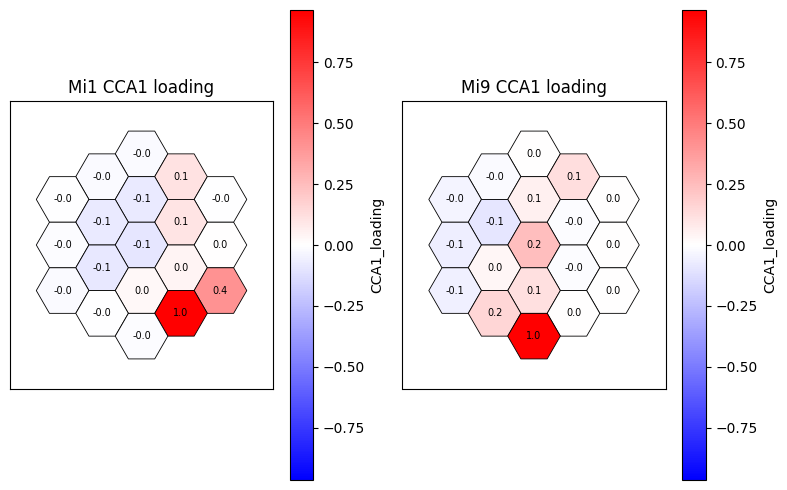

In [84]:
from utils.spatial_RF import hex_offsets
def zero_fill_offset_kernel(kernel_df, radius, value_col):
    """
    Zero-fill a kernel dataframe over all hex offsets within radius.

    kernel_df must have columns:
        dp, dq, value_col
    """
    offsets = hex_offsets(radius).copy()
    offsets["dp"] = offsets["dp"].astype(int)
    offsets["dq"] = offsets["dq"].astype(int)

    k = kernel_df.copy()
    k["dp"] = k["dp"].astype(int)
    k["dq"] = k["dq"].astype(int)

    full = offsets.merge(
        k[["dp", "dq", value_col]],
        on=["dp", "dq"],
        how="left",
    )

    full[value_col] = full[value_col].fillna(0)

    return full

load1_kernel_full = zero_fill_offset_kernel(
    load1_kernel,
    radius=RADIUS,
    value_col="CCA1_loading",
)

load2_kernel_full = zero_fill_offset_kernel(
    load2_kernel,
    radius=RADIUS,
    value_col="CCA1_loading",
)

kernels = [load1_kernel_full, load2_kernel_full]
titles = [f"{PRE_TYPE_1} CCA1 loading", f"{PRE_TYPE_2} CCA1 loading"]
from matplotlib.colors import TwoSlopeNorm

vmax = max(
    load1_kernel_full["CCA1_loading"].abs().max(),
    load2_kernel_full["CCA1_loading"].abs().max(),
)

norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

kernels = [load1_kernel_full, load2_kernel_full]
titles = [f"{PRE_TYPE_1} CCA1 loading", f"{PRE_TYPE_2} CCA1 loading"]

for ax, kernel, title in zip(axes.flat, kernels, titles):
    plot_spatial_kernel_hex(
        kernel,
        value_col="CCA1_loading",
        radius=RADIUS,
        norm=norm,
        add_colorbar=True,
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()

In [85]:
XY_corr = pd.DataFrame(
    np.corrcoef(X.T, Y.T)[:X.shape[1], X.shape[1]:],
    index=X.columns,
    columns=Y.columns
)
XY_corr

,-1_-1,-1_-2,-1_0,-2_-1,-2_-2,0_-1,0_-2,0_0,0_1,1_-1,1_0,1_1,2_0,2_1,2_2
-1_-1,-0.080170,0.365756,0.031583,-0.054598,0.029513,0.235016,0.167987,-0.116666,-0.032437,-0.060394,-0.032937,-0.125976,-0.098476,-0.100344,-0.034378
-1_-2,-0.019094,0.182450,0.087400,-0.008200,-0.007285,-0.060468,0.199567,-0.012905,-0.014164,-0.071512,-0.132486,0.014484,-0.013545,-0.030376,-0.005163
-1_0,0.207238,0.021899,-0.009359,0.444184,-0.023838,-0.054024,-0.058100,0.419515,-0.019995,-0.100211,-0.052221,0.227567,-0.071702,0.104271,-0.016896
-1_1,-0.016280,0.030246,-0.008178,-0.004034,-0.003583,-0.063783,-0.025033,0.041019,-0.006967,-0.046712,0.012535,0.322728,0.109364,-0.014941,-0.002540
-2_-1,0.176764,-0.019012,-0.011387,0.671236,0.118178,-0.034673,-0.003813,0.387526,-0.009700,-0.029349,-0.044070,0.162061,-0.029585,0.012824,-0.003536
-2_-2,-0.011965,0.263285,0.083837,-0.002964,-0.002634,-0.043599,0.257609,-0.010848,-0.005120,-0.034330,-0.044217,-0.008145,0.027072,-0.010981,-0.001867
-2_0,0.053607,-0.014146,-0.005422,-0.002674,-0.002375,-0.025860,-0.016595,-0.009785,-0.004619,-0.030966,-0.054309,-0.007347,-0.014087,-0.009905,-0.001684
0_-1,-0.146543,0.067776,-0.026062,-0.038988,-0.034636,-0.058372,0.393730,-0.135237,0.016655,0.309096,-0.217525,-0.093126,-0.029531,-0.128514,-0.024549
0_-2,-0.010279,-0.013473,-0.005164,-0.002547,-0.002263,-0.060797,0.023892,-0.009321,-0.004399,0.006915,-0.051729,-0.006998,0.048327,-0.009434,-0.001604
0_0,-0.098337,-0.029583,-0.016874,-0.094878,0.011049,0.428590,-0.126540,-0.191649,0.037359,0.048995,0.261246,-0.185680,-0.130001,-0.142485,-0.042370


In [86]:
def loadings_against_score(A, score, columns=None):
    if columns is None:
        columns = A.columns

    return pd.Series(
        [
            np.corrcoef(A.iloc[:, j], score[:, 0])[0, 1]
            for j in range(A.shape[1])
        ],
        index=columns
    )


# Own-loadings
load_X_on_Xc = loadings_against_score(X, Xc)
load_Y_on_Yc = loadings_against_score(Y, Yc)

# Cross-loadings
load_X_on_Yc = loadings_against_score(X, Yc)
load_Y_on_Xc = loadings_against_score(Y, Xc)

summary_X = pd.DataFrame({
    "mean": X.mean(axis=0),
    "var": X.var(axis=0),
    "nonzero_frac": (X > 0).mean(axis=0),
    "weight": w1,
    "own_loading_corr_X_with_Xc": load_X_on_Xc,
    "cross_loading_corr_X_with_Yc": load_X_on_Yc,
})

summary_X.sort_values(
    "cross_loading_corr_X_with_Yc",
    key=np.abs,
    ascending=False
).head(15)

,mean,var,nonzero_frac,weight,own_loading_corr_X_with_Xc,cross_loading_corr_X_with_Yc
1_2,0.076372,1.246251,0.007160,0.867736,0.963728,0.842275
0_2,0.041766,0.431945,0.004773,0.342226,0.410065,0.358412
-2_-1,0.112172,1.203651,0.013126,0.078835,0.109313,0.094884
-1_0,2.072792,18.003058,0.269690,0.030771,0.104463,0.090803
0_0,28.959427,53.484612,0.996420,0.002716,-0.092234,-0.080462
1_0,4.293556,30.881464,0.447494,-0.005243,-0.084087,-0.073376
-1_-1,6.886635,48.000275,0.640811,-0.006019,-0.078561,-0.068530
0_-1,4.939141,48.420426,0.443914,0.001173,-0.076232,-0.066477
0_1,2.760143,14.063069,0.400955,-0.003871,0.043601,0.038024
1_1,6.847255,55.885841,0.602625,0.008969,0.026181,0.022815


In [87]:
summary_Y = pd.DataFrame({
    "mean": Y.mean(axis=0),
    "var": Y.var(axis=0),
    "nonzero_frac": (Y > 0).mean(axis=0),
    "weight": w2,
    "own_loading_corr_Y_with_Yc": load_Y_on_Yc,
    "cross_loading_corr_Y_with_Xc": load_Y_on_Xc,
})

summary_Y.sort_values(
    "cross_loading_corr_Y_with_Xc",
    key=np.abs,
    ascending=False
).head(15)

,mean,var,nonzero_frac,weight,own_loading_corr_Y_with_Yc,cross_loading_corr_Y_with_Xc
2_2,0.010740,0.096659,0.001193,0.999521,0.965509,0.843719
0_0,0.630072,9.848653,0.057279,0.026737,0.246069,0.215030
2_1,0.434368,4.568567,0.048926,-0.005638,0.156774,0.136999
-2_-1,0.062053,1.279299,0.003580,-0.003880,0.122194,0.106781
1_1,0.184964,1.505771,0.025060,-0.000271,0.113637,0.099303
0_-1,9.169451,49.022626,0.755370,-0.000329,-0.091255,-0.079744
1_-1,3.780430,35.404539,0.369928,-0.000457,-0.066158,-0.057813
2_0,0.724344,6.281151,0.089499,-0.004310,-0.057987,-0.050672
-1_-1,0.457041,4.260398,0.054893,0.003183,0.057819,0.050526
0_-2,1.194511,12.307401,0.130072,-0.001092,-0.042919,-0.037505


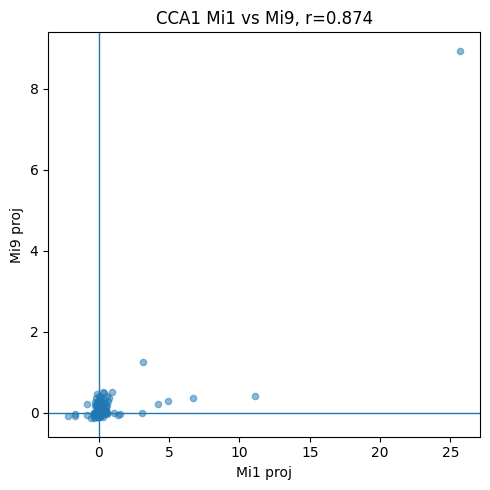

In [88]:
plt.figure(figsize=(5, 5))
plt.scatter(Xc[:, 0], Yc[:, 0], s=20, alpha=0.5)
plt.xlabel(f"{PRE_TYPE_1} proj")
plt.ylabel(f"{PRE_TYPE_2} proj")
plt.title(f"CCA1 Mi1 vs Mi9, r={np.corrcoef(Xc[:,0], Yc[:,0])[0,1]:.3f}")
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
# plt.xlim(-10,20) ; plt.ylim(-3,10)
plt.tight_layout()
plt.show()

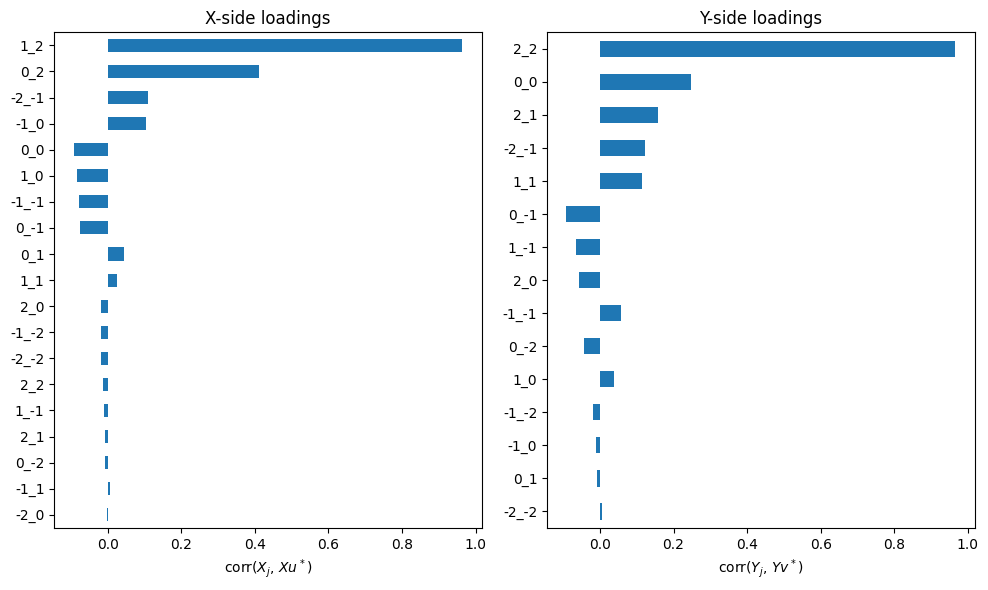

In [89]:
x_load = cca_loadings(X, Xc, component=0)
y_load = cca_loadings(Y, Yc, component=0)

top_n = 20

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

x_load.reindex(x_load.abs().sort_values().tail(top_n).index).plot.barh(ax=axes[0])
axes[0].set_title("X-side loadings")
axes[0].set_xlabel(r"corr($X_j$, $Xu^*$)")

y_load.reindex(y_load.abs().sort_values().tail(top_n).index).plot.barh(ax=axes[1])
axes[1].set_title("Y-side loadings")
axes[1].set_xlabel(r"corr($Y_j$, $Yv^*$)")

plt.tight_layout()
plt.show()

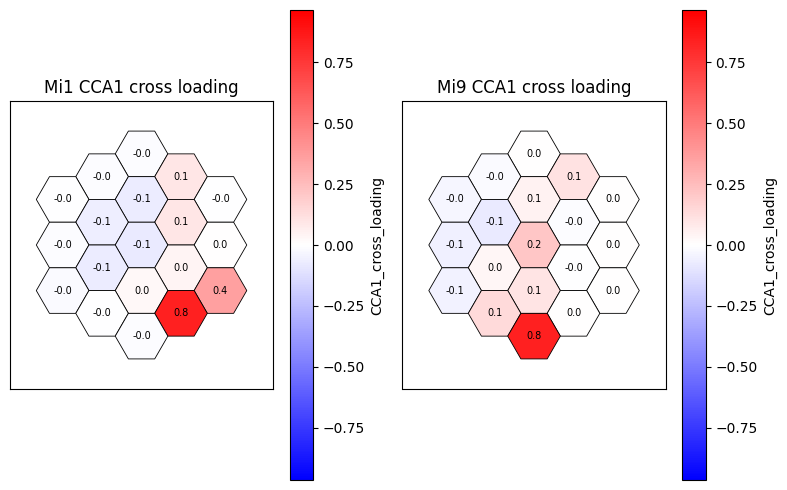

In [90]:
cross1_kernel = vector_to_kernel(load_X_on_Yc, value_name="CCA1_cross_loading")
cross2_kernel = vector_to_kernel(load_Y_on_Xc, value_name="CCA1_cross_loading")

cross1_kernel_full = zero_fill_offset_kernel(
    cross1_kernel,
    radius=RADIUS,
    value_col="CCA1_cross_loading",
)

cross2_kernel_full = zero_fill_offset_kernel(
    cross2_kernel,
    radius=RADIUS,
    value_col="CCA1_cross_loading",
)

kernels = [cross1_kernel_full, cross2_kernel_full]
titles = [f"{PRE_TYPE_1} CCA1 cross loading", f"{PRE_TYPE_2} CCA1 cross loading"]
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
for ax, kernel, title in zip(axes.flat, kernels, titles):
    plot_spatial_kernel_hex(
        kernel,
        value_col="CCA1_cross_loading",
        radius=RADIUS,
        norm=norm,
        add_colorbar=True,
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()